# Overview of Causal Inference Methods

ECON526

Paul Schrimpf (University of British Columbia)

# One Question, Many Methods

$$ %
\def\Er{{\mathrm{E}}}
\def\En{{\mathbb{E}_n}}
\def\cov{{\mathrm{Cov}}}
\def\var{{\mathrm{Var}}}
\def\R{{\mathbb{R}}}
\newcommand\norm[1]{\left\lVert#1\right\rVert}
\def\rank{{\mathrm{rank}}}
\newcommand{\inpr}{ \overset{p^*_{\scriptscriptstyle n}}{\longrightarrow}}
\def\inprob{{\,{\buildrel p \over \rightarrow}\,}}
\def\indist{\,{\buildrel d \over \rightarrow}\,}
\DeclareMathOperator*{\plim}{plim}
\def\indep{{\perp\!\!\!\perp}}
$$

## How does tutoring affect graduation rates?

- The students who choose tutoring may be different from the students
  who do not.

- A simple difference in graduation rates is not automatically a causal
  effect.

- **Causal inference requires a credible comparison for what would have
  happened otherwise.**

## What could make a comparison credible?

### The question

- Does tutoring increase graduation?

  - **Treatment:** tutoring
  - **Outcome:** graduation
  - **Population:** students eligible for tutoring

### The missing comparison

- For tutored students, we observe graduation **with** tutoring.

- We do not observe how those same students would have done **without**
  tutoring.

Every method below proposes a different way to build that
counterfactual.

# Where Does Identification Come From?

## A field guide

| Method | Compare… | Key idea |
|------------------------|------------------------|------------------------|
| Experiment | randomly assigned groups | assignment breaks selection |
| Regression / matching | similar observed students | adjust for observed differences |
| Difference in differences | changes over time | comparison group captures the trend |
| Synthetic control | treated place vs weighted donor places | match the pre-treatment path |
| Instrumental variables | treatment shifted by an instrument | isolate a plausibly external nudge |
| Regression discontinuity | units just either side of a cutoff | near-cutoff units are comparable |

Each method relies on assumptions that make its comparison informative
about a causal effect. The available data and institutional setting
determine what method to use.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("tableau-colorblind10")
rng = np.random.default_rng(526)

# Experiments and Observational Comparisons

## Random assignment: the clean benchmark

- A school district has more eligible students than tutoring places. It
  randomly offers places to some students and compares their graduation
  rates.

**Offer of tutoring** for randomly selected eligible students

**No offer** for other eligible students

- Because the offer was random, there is no selection bias and the two
  groups provide a comparison for each other. $$
  Y(1), Y(0) | D \, \Rightarrow\, \Er[Y(1) | D = 1] - \Er[Y(0) | D = 0] = \Er[Y(1) - Y(0)]
  $$

- The graduation-rate gap estimates the effect of being offered
  tutoring.

## Randomized experiment

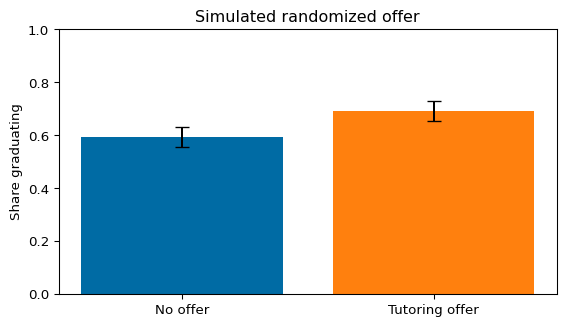

In [3]:
n = 1200
offer = rng.binomial(1, 0.5, n)
prior_score = rng.normal(size=n)
p_graduate = 1 / (1 + np.exp(-(0.4 + 0.45 * prior_score + 0.5 * offer)))
graduated = rng.binomial(1, p_graduate)

means = np.array([graduated[offer == d].mean() for d in (0, 1)])
ses = np.array([
    np.sqrt(means[d] * (1 - means[d]) / np.sum(offer == d))
    for d in (0, 1)
])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([0, 1], means, yerr=1.96 * ses, capsize=5, color=["C0", "C1"])
ax.set_xticks([0, 1], ["No offer", "Tutoring offer"])
ax.set_ylim(0, 1)
ax.set_ylabel("Share graduating")
ax.set_title("Simulated randomized offer")
plt.tight_layout()
plt.show()

> **Note**
>
> Randomization helps with selection into an offer. It does not
> eliminate concerns like attrition, noncompliance, or whether results
> apply to students in other districts.

## Regression and matching: make like-with-like comparisons

### Tutoring, revisited

- Tutored students often had lower grades before tutoring.

- **Compare students with similar prior grades and backgrounds** —using
  regression adjustment or matching.

- **Identification assumption:** conditional on observed
  characteristics, tutoring is as good as randomly assigned. $$
  Y(1), Y(0) \indep D | X
  $$

- **Question to ask:** what important difference is still unobserved?

- All relevant differences should be measured, or there could be
  selection conditional on covariates
  - Motivation, family support, or a teacher’s private assessment may
    still affect both tutoring and graduation.

## Matching

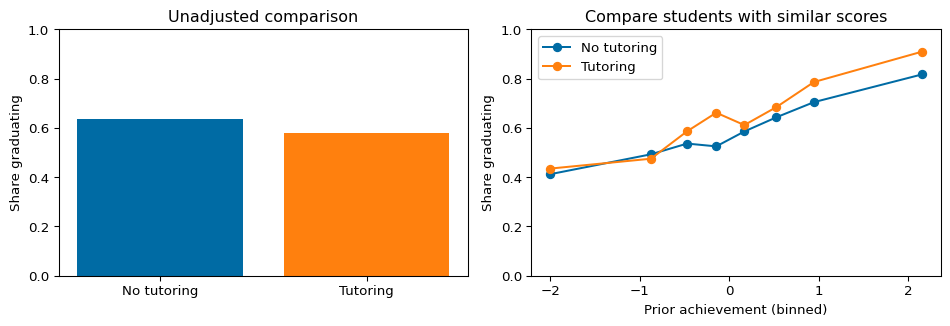

In [4]:
n = 1800
score = rng.normal(size=n)
p_tutor = 1 / (1 + np.exp(0.2 + 1.2 * score))
tutoring = rng.binomial(1, p_tutor)
p0 = 1 / (1 + np.exp(-(0.25 + 0.65 * score)))
p1 = np.clip(p0 + 0.12, 0, 1)
graduated = rng.binomial(1, np.where(tutoring == 1, p1, p0))

edges = np.quantile(score, np.linspace(0, 1, 9))
centers = (edges[:-1] + edges[1:]) / 2
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for d, color, label in [(0, "C0", "No tutoring"), (1, "C1", "Tutoring")]:
    raw_mean = graduated[tutoring == d].mean()
    axes[0].bar(d, raw_mean, color=color, label=label)
    rates = [
        graduated[(tutoring == d) & (score >= lo) & (score < hi)].mean()
        for lo, hi in zip(edges[:-1], edges[1:])
    ]
    axes[1].plot(centers, rates, "o-", color=color, label=label)
axes[0].set_xticks([0, 1], ["No tutoring", "Tutoring"])
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Share graduating")
axes[0].set_title("Unadjusted comparison")
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Prior achievement (binned)")
axes[1].set_ylabel("Share graduating")
axes[1].set_title("Compare students with similar scores")
axes[1].legend()
plt.tight_layout()
plt.show()

# Variation over Time and Across Places

## Difference in differences: compare changes

- **The district expands tutoring in some schools this year, but not in
  others.** Compare graduation rates before and after the expansion:

  - Potential outcomes $Y_{it}(d)$
    - Making these only depend on current $d$ implies (i) no
      anticipation (ii) no spillovers
  - Observe $Y_{it} = Y_{it}(D_{it})$

Observed Outcomes \| \| Before \| After \| \|—\|—:\|—:\| \| Expansion
schools \| $Y_{i0}(0)$ \| $Y_{i1}(1)$ \| \| Other schools \| $Y_{j0}(0)$
\| $Y_{j1}(0)$ \|

- Difference in difference:

$$
\underbrace{(Y_{i1}(1)-Y_{i0}(0))}_{\text{treated school's change}}
-\underbrace{(Y_{j1}(1)-Y_{j0}(0))}_{\text{comparison school's change}}
$$

- The other schools’ change stands in for expansion schools’ missing
  no-tutoring-expansion trend.

## Difference in differences

> **Note**
>
> **Key assumption: parallel trends.** Without the expansion, graduation
> rates in the two sets of schools would have changed similarly. $$
> \underbrace{\Er[\textcolor{red}{Y_{i1}(0)} - Y_{i0}(0) | D_{i1}=1]}_{\text{\textcolor{red}{unobserved}}} = \underbrace{\Er[Y_{i1}(0) - Y_{i0}(0) | D_{i1}=0]}_{\text{observed}}
> $$ - Implies: $$
> \begin{align*}
> \text{DiD} = & \Er[Y_{i1}(1) - Y_{i0}(0) | D_{i1}=1] - \Er[Y_{i1}(0) - Y_{i0}(0) | D_{i1}=0] \\
> = & \Er[Y_{i1}(1) - Y_{i0}(0) | D_{i1}=1] - \Er[\textcolor{red}{Y_{i1}(0)} - Y_{i0}(0) | D_{i1}=1] \\
> = & \Er[Y_{i1}(1) - \textcolor{red}{Y_{i1}(0)} | D_{i1}=1] = \text{ATT}
> $$

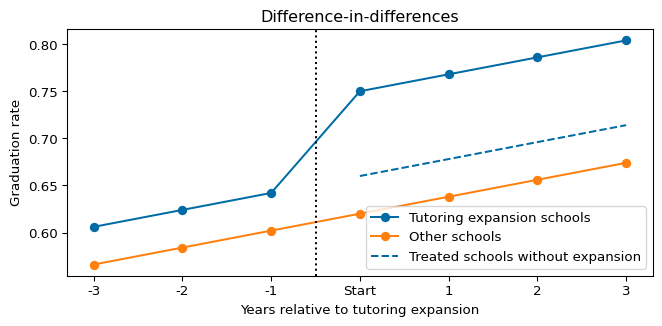

In [5]:
period = np.arange(-3, 4)
baseline = 0.62
trend = 0.018
effect = 0.09
control = baseline + trend * period
treated_counterfactual = baseline + 0.04 + trend * period
treated_observed = treated_counterfactual + (period >= 0) * effect

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(period, treated_observed, "o-", label="Tutoring expansion schools")
ax.plot(period, control, "o-", label="Other schools")
ax.plot(period[period >= 0], treated_counterfactual[period >= 0],
        "--", color="C0", label="Treated schools without expansion")
ax.axvline(-0.5, color="black", linestyle=":")
ax.set_xticks(period, ["-3", "-2", "-1", "Start", "1", "2", "3"])
ax.set_xlabel("Years relative to tutoring expansion")
ax.set_ylabel("Graduation rate")
ax.set_title("Difference-in-differences")
ax.legend()
plt.tight_layout()
plt.show()

## Assessing Parallel Trends

- Thinking about how treatment was assigned helps assess plausibility of
  parallel trends
- Self-selection into treatment can be problematic
  - E.g. if schools expanded tutoring because teachers noticed that
    students were increasingly struggling and the teachers expected
    graduation rates to fall
    - $\Er[\textcolor{red}{Y_{i1}(0)} - Y_{i0}(0) | D_{i1}=1] \neq \Er[Y_{i1}(0) - Y_{i0}(0) | D_{i1}=0]$
    - Might show up in pre-treatment trends, if observe $t=-1$, can
      check whether $$
         \Er[Y_{i,0}(0) - Y_{i,-1}(0) | D_{i1}=1] = \Er[Y_{i,0}(0) - Y_{i,-1}(0) | D_{i1}=0]$
         $$
- Conditioning can sometimes help
  - Conditional parallel trends $$
     \Er[\textcolor{red}{Y_{i1}(0)} - Y_{i0}(0) | D_{i1}=1, X_i] \neq \Er[Y_{i1}(0) - Y_{i0}(0) | D_{i1}=0, X_i]
     $$

## Synthetic control: build a comparison district

### The district expands tutoring everywhere

Suppose one district introduces a tutoring program across all its
schools at once, and other districts do not. What would graduation rates
have been without it?

1.  Weight other districts to resemble this district **before** the
    program.
2.  Compare its post-program path with this “synthetic district.”
3.  Treat the post-program gap as an estimated effect—if donor districts
    provide a credible counterfactual.

## Synthetic Control

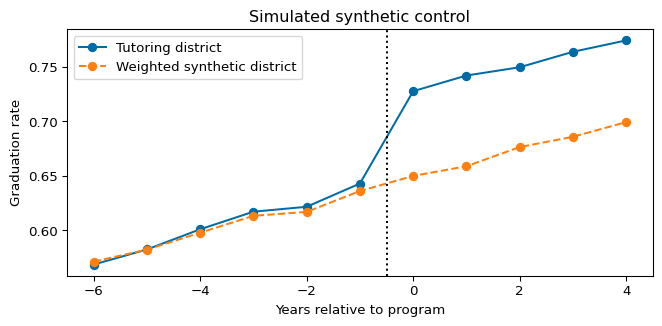

In [6]:
years = np.arange(-6, 5)
donors = 10
donor_level = rng.normal(0.65, 0.05, donors)
donor_trend = rng.normal(0.012, 0.004, donors)
donor_outcomes = np.array([
    level + trend * years + rng.normal(0, 0.006, len(years))
    for level, trend in zip(donor_level, donor_trend)
])
weights = np.array([0.28, 0.22, 0.18, 0.12, 0.08, 0.04, 0.03, 0.02, 0.02, 0.01])
synthetic = weights @ donor_outcomes
treated = synthetic + rng.normal(0, 0.004, len(years))
treated[years >= 0] += 0.08

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(years, treated, "o-", label="Tutoring district")
ax.plot(years, synthetic, "o--", label="Weighted synthetic district")
ax.axvline(-0.5, color="black", linestyle=":")
ax.set_xlabel("Years relative to program")
ax.set_ylabel("Graduation rate")
ax.set_title("Simulated synthetic control")
ax.legend()
plt.tight_layout()
plt.show()

## Synthetic Control or Difference in Differences?

- Both need panel data with some units treated, others untreated

- Synthetic Control:
  - best for one or few treated units, many untreated units, many
    pre-treatment periods
  - Assumption: convex combination of untreated units resembles treated
    unit
    - Valid if untreated potential outcome follows a factor model $$
      Y_{it}(0) = X_{it}' \beta + \underbrace{\lambda_i'
      \theta_t}_{\text{unobserved interactive effects (or factors)}} + \epsilon_{it}
      $$

- Difference in differences:
  - many treated and untreated units, okay with fewer periods
  - Assumption: Parallel trends

# Instruments and Cutoffs

## Instrumental variables: use an external nudge

Return to the tutoring lottery: some students offered a place do not
attend, while a few students not offered find tutoring elsewhere.

**Lottery offer** $\longrightarrow$ **tutoring attendance**
$\longrightarrow$ **graduation**

- The offer, $Z_i$, can instrument for attendance if it changes
  participation. $$ \cov(Z_i,D_i) \neq 0 $$
- The offer must be unrelated to other causes of graduation. $$
  Z_i \indep Y(0), Y(1), D(z)
  $$
- It must affect graduation through tutoring, not through another
  channel.
  - Potential outcomes are $Y(D(Z))$, not $Y(D,Z)$.

IV estimates an effect for students whose tutoring attendance responds
to the offer—not necessarily for everyone.

## IV

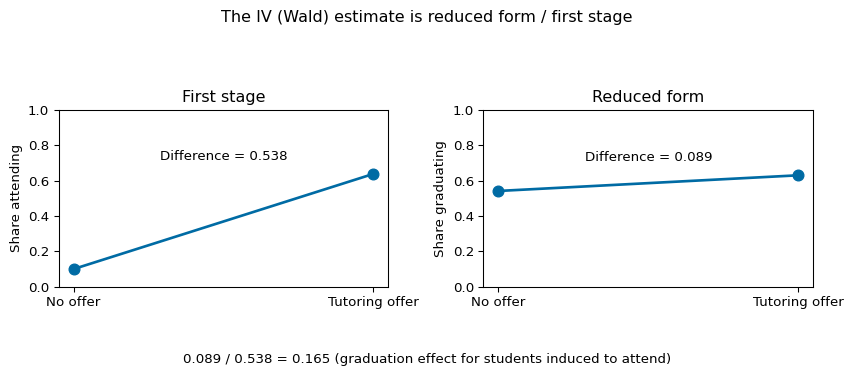

In [7]:
n = 1500
offer = rng.binomial(1, 0.5, n)
motivation = rng.normal(size=n)
compliance_type = rng.choice(["always", "complier", "never"], n, p=[0.1, 0.55, 0.35])
attend = ((compliance_type == "always")
          | ((compliance_type == "complier") & (offer == 1))).astype(int)

p0 = 1 / (1 + np.exp(-(0.15 + 0.6 * motivation)))
p1 = np.minimum(p0 + 0.12, 0.98)
outcome_shock = rng.uniform(size=n)
graduated = np.where(outcome_shock < np.where(attend == 1, p1, p0), 1, 0)

first_stage = attend[offer == 1].mean() - attend[offer == 0].mean()
reduced_form = graduated[offer == 1].mean() - graduated[offer == 0].mean()
iv_estimate = reduced_form / first_stage

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, outcome, title, ylabel, difference in [
    (axes[0], attend, "First stage", "Share attending", first_stage),
    (axes[1], graduated, "Reduced form", "Share graduating", reduced_form),
]:
    means = [outcome[offer == z].mean() for z in (0, 1)]
    ax.plot([0, 1], means, "o-", linewidth=2, markersize=8)
    ax.annotate(f"Difference = {difference:.3f}",
                xy=(0.5, max(means) + 0.08), ha="center")
    ax.set_ylim(0, 1)
    ax.set_ylabel(ylabel)
    ax.set_xticks([0, 1], ["No offer", "Tutoring offer"])
    ax.set_title(title)
fig.suptitle("The IV (Wald) estimate is reduced form / first stage")
fig.text(0.5, 0.01,
         f"{reduced_form:.3f} / {first_stage:.3f} = {iv_estimate:.3f} "
         "(graduation effect for students induced to attend)",
         ha="center")
fig.tight_layout(rect=[0, 0.12, 1, 0.88])
plt.show()

## Regression discontinuity: compare just around the line

- A school offers tutoring to students whose baseline math score is
  **below 60**.

- Compare students scoring just below and just above 60—not students far
  apart in preparation.

**Why might that work?**

Students very close to the cutoff may be similar. If graduation rates
would otherwise change smoothly around 60, a jump in graduation
identifies the effect of **eligibility**. If eligibility affects
graduation only by changing tutoring attendance, the cutoff can also
identify a local effect of tutoring for students whose attendance it
changes.

- Assumption: continuity of $\Er[Y(1)|R=r]$ and $\Er[Y(0)|R=r]$

- **Watch for:** students or teachers manipulating scores near the
  threshold. The estimate is local to students around the cutoff.

## Regression Discontinuity

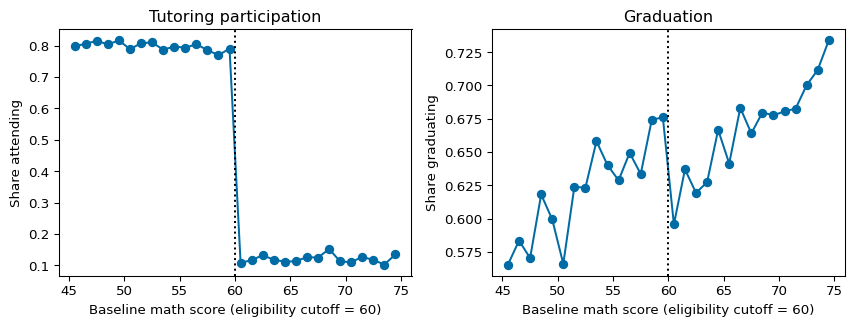

In [8]:
n = 32_000
score = rng.uniform(45, 75, n)
eligible = (score < 60).astype(int)
p_attend = np.where(eligible == 1, 0.8, 0.12)
attend = rng.binomial(1, p_attend)
p_graduate = np.clip(0.6 + 0.008 * (score-60) + 0.10 * attend, 0, 1)
graduated = rng.binomial(1, p_graduate)
bins = np.linspace(45, 75, 31)
centers = (bins[:-1] + bins[1:]) / 2
attendance_rate = [
    attend[(score >= lo) & (score < hi)].mean()
    for lo, hi in zip(bins[:-1], bins[1:])
]
graduation_rate = [
    graduated[(score >= lo) & (score < hi)].mean()
    for lo, hi in zip(bins[:-1], bins[1:])
]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(centers, attendance_rate, "o-")
axes[0].set_title("Tutoring participation")
axes[0].set_ylabel("Share attending")
axes[1].plot(centers, graduation_rate, "o-")
axes[1].set_title("Graduation")
axes[1].set_ylabel("Share graduating")
for ax in axes:
    ax.axvline(60, color="black", linestyle=":")
    ax.set_xlabel("Baseline math score (eligibility cutoff = 60)")
plt.tight_layout()
plt.show()

# Flexible Estimation and Effects

## Does tutoring help everyone equally?

An average effect can hide important differences:

### Ask

Is tutoring more effective for students with weaker prior preparation?

### Then check

Can the method identify effects for those groups? Were the groups chosen
before looking at results?

- I.e. interested in conditional treatment effects,
  $\Er[Y(1) - Y(0) | X]$

- Searching many subgroups can produce impressive-looking patterns by
  chance. Treat discovered heterogeneity skeptically.

## Conditional Treatment Effects

Simulate a randomized tutoring study where the true effect is **the same
in every group**. Explore 15 categories anyway: some nominal 95%
confidence intervals may miss the common effect just by chance.

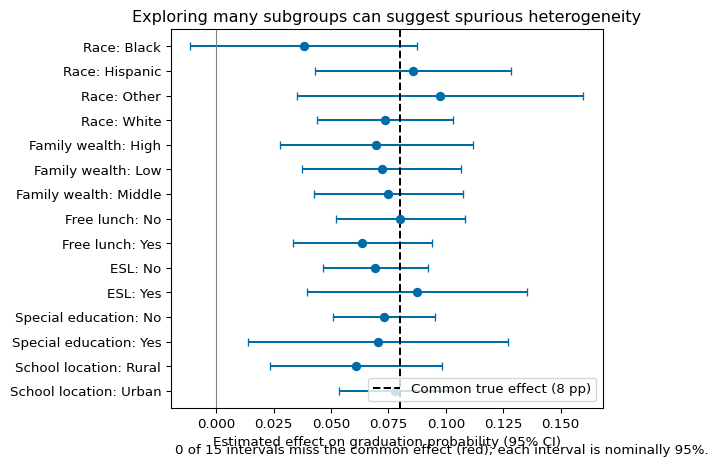

In [9]:
n = 8000
group_rng = np.random.default_rng(52613)
groups = {
    "Race": group_rng.choice(["Black", "Hispanic", "White", "Other"], n,
                             p=[0.18, 0.24, 0.48, 0.10]),
    "Family wealth": group_rng.choice(["Low", "Middle", "High"], n,
                                     p=[0.35, 0.40, 0.25]),
    "Free lunch": group_rng.choice(["Yes", "No"], n, p=[0.45, 0.55]),
    "ESL": group_rng.choice(["Yes", "No"], n, p=[0.18, 0.82]),
    "Special education": group_rng.choice(["Yes", "No"], n, p=[0.12, 0.88]),
    "School location": group_rng.choice(["Rural", "Urban"], n, p=[0.3, 0.7]),
}

score = group_rng.normal(size=n)
tutoring = group_rng.binomial(1, 0.5, n)
true_effect = 0.08
p0 = np.clip(0.62 + 0.05 * score, 0.15, 0.85)
graduated = group_rng.binomial(1, p0 + true_effect * tutoring)

labels = []
estimates = []
ses = []
for variable, values in groups.items():
    for category in np.unique(values):
        in_group = values == category
        treated_y = graduated[in_group & (tutoring == 1)]
        control_y = graduated[in_group & (tutoring == 0)]
        estimate = treated_y.mean() - control_y.mean()
        se = np.sqrt(
            treated_y.var() / len(treated_y)
            + control_y.var() / len(control_y)
        )
        labels.append(f"{variable}: {category}")
        estimates.append(estimate)
        ses.append(se)

estimates = np.array(estimates)
ses = np.array(ses)
lo = estimates - 1.96 * ses
hi = estimates + 1.96 * ses
misses_truth = (lo > true_effect) | (hi < true_effect)
ypos = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(9, 6))
for i in range(len(labels)):
    color = "C3" if misses_truth[i] else "C0"
    ax.errorbar(estimates[i], ypos[i], xerr=1.96 * ses[i], fmt="o",
                capsize=3, color=color)
ax.axvline(true_effect, color="black", linestyle="--",
           label="Common true effect (8 pp)")
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_yticks(ypos, labels)
ax.invert_yaxis()
ax.set_xlabel("Estimated effect on graduation probability (95% CI)")
ax.set_title("Exploring many subgroups can suggest spurious heterogeneity")
ax.legend(loc="lower right")
ax.text(0.01, -0.12,
        f"{misses_truth.sum()} of {len(labels)} intervals miss the common effect "
        "(red); each interval is nominally 95%.",
        transform=ax.transAxes)
fig.tight_layout(rect=[0.28, 0.16, 1, 1])
plt.show()

## Distribution Effects

- Instead of (conditional) average effects, we can look at changes in
  distribution
  - Distribution functions: $F_{Y(1)}(y) - F_{Y(0)}(y)$
  - Quantiles: $Q_{\tau}(Y(1)) - Q_{\tau}(Y(0))$

# Project Proposal

## Project proposal — due November 13

Briing a focused causal question

Your proposal should include:

- question
- treatment
- outcome
- data
- comparison
- key assumptions

As we study each method, ask: *Could its identifying assumptions be
credible for my question and data?*